In [1]:
import mlflow
from dotenv import load_dotenv
from os import getenv
import numpy as np
import time
import pandas as pd
import matplotlib.pyplot as plt
from typing import List
from math import ceil

In [ ]:
# Mlflow setup
env_path = "../../ml.env"
load_dotenv(env_path)

mlflow.set_tracking_uri(getenv("MLFLOW_TRACKING_URI"))
print(mlflow.get_tracking_uri())

https://172.27.62.170:5001/


In [3]:
# Load models
logistic_regression = mlflow.sklearn.load_model("models:/weakest_link_model/5")
knn5 = mlflow.sklearn.load_model("models:/weakest_link_model/6")
lightgbm = mlflow.sklearn.load_model("models:/weakest_link_model/8")
gaussian_nb = mlflow.sklearn.load_model("models:/weakest_link_model/10")
lda = mlflow.sklearn.load_model("models:/weakest_link_model/11")
hist_gradient_boosting_tree = mlflow.sklearn.load_model("models:/weakest_link_model/4")
svm = mlflow.sklearn.load_model("models:/weakest_link_model/12")

/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.13/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.13/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.13/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being 

In [9]:
# Load features

# Features from logistic regression. All models uses the same features, so loading the features
# from any classification model is ok.
features = logistic_regression.feature_names_in_
data_frame_hgbt_svm = hist_gradient_boosting_tree.feature_names_in_

In [10]:
# Build sample inputs
runs = 2000
np.random.seed(1)
raw_input = np.array([[np.random.random() for _ in range(38)] for _ in range(runs)])
data_frame = pd.DataFrame(columns=features, data=raw_input)
data_frame_hgbt_svm = pd.DataFrame(columns=data_frame_hgbt_svm, data=raw_input)
print(f"Feature count: {data_frame.shape[1]}")
data_frame

Feature count: 38


,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,No_10_Angle_Deviation,...,No_16_NASM_Deviation,No_17_NASM_Deviation,No_18_NASM_Deviation,No_19_NASM_Deviation,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation
0,0.417022,0.720324,0.000114,0.302333,0.146756,0.092339,0.186260,0.345561,0.396767,0.538817,...,0.169830,0.878143,0.098347,0.421108,0.957890,0.533165,0.691877,0.315516,0.686501,0.834626
1,0.018288,0.750144,0.988861,0.748166,0.280444,0.789279,0.103226,0.447894,0.908596,0.293614,...,0.663795,0.514889,0.944595,0.586555,0.903402,0.137475,0.139276,0.807391,0.397677,0.165354
2,0.927509,0.347766,0.750812,0.725998,0.883306,0.623672,0.750942,0.348898,0.269928,0.895886,...,0.908535,0.623360,0.015821,0.929437,0.690897,0.997323,0.172341,0.137136,0.932595,0.696818
3,0.066000,0.755463,0.753876,0.923025,0.711525,0.124271,0.019880,0.026211,0.028306,0.246211,...,0.059918,0.121343,0.044552,0.107494,0.225709,0.712989,0.559717,0.012556,0.071974,0.967276
4,0.568100,0.203293,0.252326,0.743826,0.195429,0.581359,0.970020,0.846829,0.239848,0.493770,...,0.629718,0.210174,0.752756,0.066536,0.260315,0.804755,0.193434,0.639461,0.524670,0.924808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.804800,0.206670,0.349938,0.633565,0.668642,0.430935,0.622844,0.338095,0.680890,0.251496,...,0.509430,0.281183,0.093306,0.134537,0.862921,0.090578,0.598048,0.757446,0.881318,0.060440
1996,0.826655,0.210078,0.348892,0.680322,0.009184,0.623187,0.636534,0.295674,0.925737,0.796178,...,0.305755,0.369647,0.764490,0.718945,0.749427,0.791732,0.047846,0.501971,0.735063,0.562087
1997,0.590012,0.953924,0.001515,0.315365,0.645775,0.918614,0.447225,0.647151,0.393348,0.950047,...,0.512921,0.984910,0.880554,0.780030,0.224710,0.887655,0.732115,0.265647,0.363372,0.532219
1998,0.005307,0.393306,0.585357,0.847980,0.596558,0.865093,0.218447,0.889021,0.637668,0.106708,...,0.321689,0.584630,0.067661,0.389422,0.927586,0.191977,0.300564,0.268143,0.553406,0.911901


In [11]:

models = {
    "logistic_regression": (logistic_regression, np.zeros(runs, dtype=float), data_frame),
    "knn5": (knn5, np.zeros(runs, dtype=float), data_frame),
    "lightgbm": (lightgbm, np.zeros(runs, dtype=float), data_frame),
    "gaussian_nb": (gaussian_nb, np.zeros(runs, dtype=float), data_frame),
    "lda": (lda, np.zeros(runs, dtype=float), data_frame),
    "hist_gradient_boosting_tree": (hist_gradient_boosting_tree, np.zeros(runs, dtype=float), data_frame_hgbt_svm),
    "svm": (svm, np.zeros(runs, dtype=float), data_frame_hgbt_svm)
}

In [12]:
def build_random_sample(feature_columns: List[str]) -> pd.DataFrame:
    raw_input = np.array([[np.random.random() for _ in range(len(feature_columns))]])
    return pd.DataFrame(columns=feature_columns, data=raw_input)

In [13]:
warm_up_rounds = 100

for model_name, (model, times, data_frame) in models.items():

    # cache warmup
    warm_row = data_frame.loc[[0]]
    for _ in range(warm_up_rounds):
        model.predict(warm_row)
        
    # Experiment execution
    for i in range(runs):
        row = data_frame.loc[[i]]
        start = time.perf_counter()
        model.predict(row)
        stop = time.perf_counter()

        diff = (stop - start) * 1000 # ms
        times[i] = diff


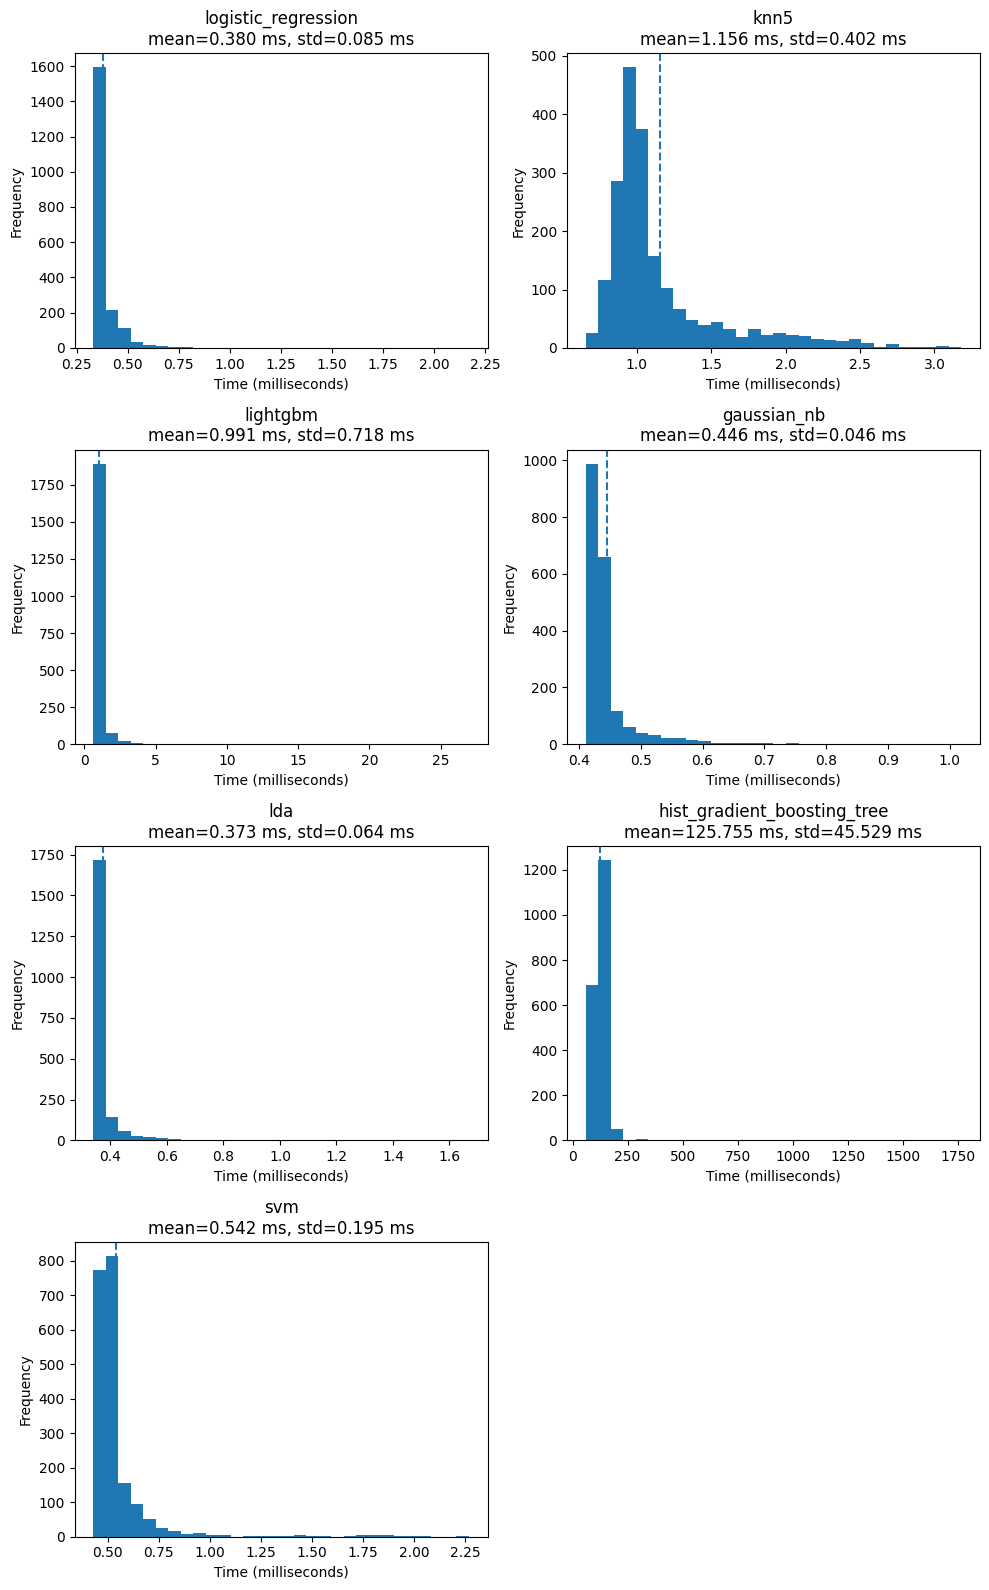

In [14]:
# Plotting

n_models = len(models)

cols = 2
rows = ceil(n_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(10, 4 * rows))
axes = axes.flatten()

for i, (model_name, (_, times, _)) in enumerate(models.items()):
    
    times = np.array(times)

    mean_val = np.mean(times)
    std_val = np.std(times)

    axes[i].hist(times, bins=30)

    # mean line
    axes[i].axvline(mean_val, linestyle="--")

    axes[i].set_title(
        f"{model_name}\nmean={mean_val:.3f} ms, std={std_val:.3f} ms"
    )

    axes[i].set_xlabel("Time (milliseconds)")
    axes[i].set_ylabel("Frequency")


# Remove empty plots if number of models is odd
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

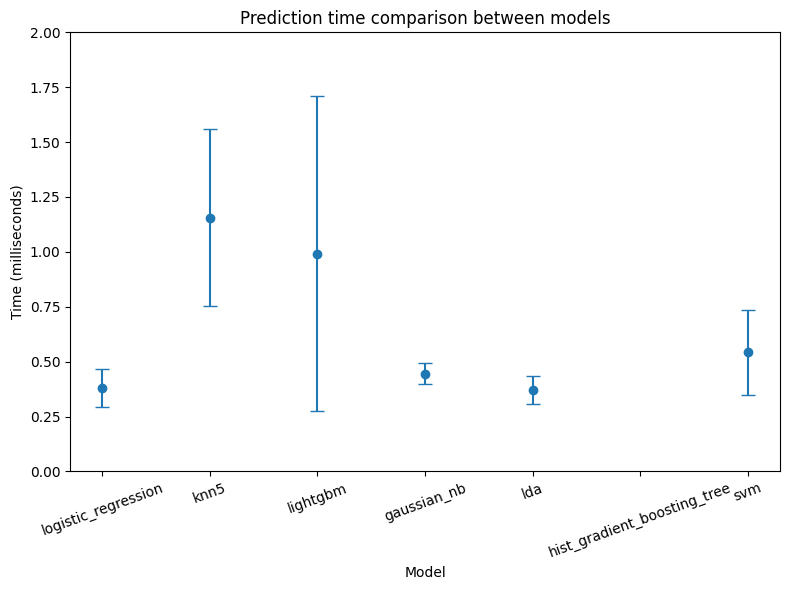

In [19]:
model_names = []
means = []
stds = []

for model_name, (_, times, _) in models.items():
    model_names.append(model_name)

    means.append(np.mean(times))
    stds.append(np.std(times))


x = np.arange(len(model_names))

plt.figure(figsize=(8, 6))


plt.errorbar(
    x,
    means,
    yerr=stds,
    fmt='o',
    capsize=5
)

plt.xticks(x, model_names, rotation=20)

plt.ylim(0, 2)

plt.title("Prediction time comparison between models")
plt.ylabel("Time (milliseconds)")
plt.xlabel("Model")

plt.tight_layout()
plt.show()